# 5.4. Порівняння CNN, крос-валідація та збереження

Чотири архітектури: базова, складна з умови, глибока і ще глибша. Перевіряємо learning_rate. Налаштовуємо моделі за validation, не за test чи зовнішніми цифрами. Окремо виконуємо 5-fold та фінальне навчання на всіх 60 000 прикладах.

In [1]:
from pathlib import Path  # Підключаємо бібліотеку або інструмент: pathlib Path.
import json, time  # Підключаємо бібліотеку або інструмент: json, time.
import numpy as np  # Підключаємо бібліотеку або інструмент: numpy as np.
import matplotlib.pyplot as plt  # Підключаємо бібліотеку або інструмент: matplotlib.pyplot as plt.
import tensorflow as tf  # Підключаємо бібліотеку або інструмент: tensorflow as tf.
from tensorflow import keras  # Підключаємо бібліотеку або інструмент: tensorflow keras.
from sklearn.model_selection import train_test_split, StratifiedKFold  # Підключаємо бібліотеку або інструмент: sklearn.model_selection train_test_split, StratifiedKFold.
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay  # Підключаємо бібліотеку або інструмент: sklearn.metrics classification_report, confusion_matrix, ConfusionMatrixDisplay.

# У Colab файли створюються в поточній папці; у репозиторії — в його корені.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()  # Обчислюємо та зберігаємо значення у змінній ROOT.
for folder in ('models', 'results'):  # Повторюємо вкладені дії для кожного елемента циклу.
    (ROOT/folder).mkdir(exist_ok=True)  # Обчислюємо та зберігаємо значення у змінній (ROOT/folder).mkdir(exist_ok.
keras.utils.set_random_seed(42)  # Фіксуємо генератор випадкових чисел для відтворюваного досліду.
print('TensorFlow:', tf.__version__, 'Keras:', keras.__version__)  # Виводимо поточний результат або перевірочні значення.
print('Пристрої:', tf.config.list_physical_devices())  # Виводимо поточний результат або перевірочні значення.

TensorFlow: 2.21.0 Keras: 3.13.2
Пристрої: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
(raw_train, labels_train), (raw_test, labels_test) = keras.datasets.mnist.load_data()  # Завантажуємо набір MNIST із зображеннями та правильними мітками.
# Однаковий стратифікований поділ для чесного порівняння всіх архітектур.
indices_train, indices_val = train_test_split(  # Створюємо окремі тренувальну й перевірочну частини даних.
    np.arange(len(raw_train)), test_size=10000, stratify=labels_train, random_state=42)  # Обчислюємо та зберігаємо значення у змінній np.arange(len(raw_train)), test_size.
print('Train:', len(indices_train), 'validation:', len(indices_val), 'test:', len(raw_test))  # Виводимо поточний результат або перевірочні значення.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: 50000 validation: 10000 test: 10000


In [3]:
cnn_all = raw_train.astype('float32')[..., None] / 255.0  # Нормалізуємо яскравість пікселів до діапазону від нуля до одиниці.
cnn_test = raw_test.astype('float32')[..., None] / 255.0  # Нормалізуємо яскравість пікселів до діапазону від нуля до одиниці.
cnn_targets = keras.utils.to_categorical(labels_train, 10)  # Перетворюємо мітки цифр на one-hot вектори з десяти класів.
cnn_test_targets = keras.utils.to_categorical(labels_test, 10)  # Перетворюємо мітки цифр на one-hot вектори з десяти класів.
print(cnn_all.shape, cnn_targets.shape, cnn_all.min(), cnn_all.max())  # Виводимо поточний результат або перевірочні значення.

(60000, 28, 28, 1) (60000, 10) 0.0 1.0


## 1. Архітектури
Conv2D вивчає локальні ознаки, MaxPooling зменшує карту ознак, Dropout знижує перенавчання, Flatten перетворює карти на вектор. BatchNormalization у четвертій моделі стабілізує активації. Додаткова глибина не гарантує кращого результату.

In [4]:
def build_cnn(architecture, learning_rate=0.001):  # Оголошуємо функцію; її назва показує, яку дію вона виконує.
    L = keras.layers  # Обчислюємо та зберігаємо значення у змінній L.
    layers = [L.Input((28, 28, 1))]  # Обчислюємо та зберігаємо значення у змінній layers.
    if architecture == 'basic':  # Перевіряємо умову й виконуємо вкладений код лише коли вона істинна.
        layers += [L.Conv2D(32, 5, activation='relu'), L.MaxPooling2D(2), L.Dropout(.2), L.Flatten(), L.Dense(128, activation='relu')]  # Додаємо згортковий шар, що знаходить локальні ознаки зображення.
    elif architecture == 'complex':  # Перевіряємо наступний можливий випадок.
        layers += [L.Conv2D(30, 5, activation='relu'), L.MaxPooling2D(2), L.Conv2D(15, 3, activation='relu'),  # Додаємо згортковий шар, що знаходить локальні ознаки зображення.
                   L.MaxPooling2D(2), L.Dropout(.2), L.Flatten(), L.Dense(128, activation='relu'), L.Dense(50, activation='relu')]  # Зменшуємо карту ознак, залишаючи найсильніші сигнали.
    elif architecture == 'deep':  # Перевіряємо наступний можливий випадок.
        layers += [L.Conv2D(32, 3, padding='same', activation='relu'), L.Conv2D(32, 3, activation='relu'), L.MaxPooling2D(2),  # Додаємо згортковий шар, що знаходить локальні ознаки зображення.
                   L.Dropout(.2), L.Conv2D(64, 3, padding='same', activation='relu'), L.Conv2D(64, 3, activation='relu'),  # Додаємо згортковий шар, що знаходить локальні ознаки зображення.
                   L.MaxPooling2D(2), L.Dropout(.3), L.Flatten(), L.Dense(128, activation='relu'), L.Dropout(.4)]  # Зменшуємо карту ознак, залишаючи найсильніші сигнали.
    elif architecture == 'deeper':  # Перевіряємо наступний можливий випадок.
        for filters in (32, 64, 96):  # Повторюємо вкладені дії для кожного елемента циклу.
            layers += [L.Conv2D(filters, 3, padding='same', use_bias=False), L.BatchNormalization(), L.Activation('relu'),  # Додаємо згортковий шар, що знаходить локальні ознаки зображення.
                       L.Conv2D(filters, 3, padding='same', activation='relu'), L.MaxPooling2D(2), L.Dropout(.2)]  # Додаємо згортковий шар, що знаходить локальні ознаки зображення.
        layers += [L.Flatten(), L.Dense(128, activation='relu'), L.Dropout(.4)]  # Випадково вимикаємо частину нейронів під час навчання для регуляризації.
    else:  # Обробляємо решту випадків, коли попередні умови не підійшли.
        raise ValueError(architecture)  # Зупиняємо виконання з повідомленням про помилковий стан.
    layers += [L.Dense(10, activation='softmax')]  # Додаємо повнозв’язний шар; останній шар формує оцінки десяти цифр.
    model = keras.Sequential(layers, name='cnn_'+architecture)  # Обчислюємо та зберігаємо значення у змінній model.
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss='categorical_crossentropy', metrics=['accuracy'])  # Обираємо функцію втрат для міток у форматі one-hot.
    return model  # Повертаємо результат функції до місця її виклику.

In [5]:
for architecture in ('basic', 'complex', 'deep', 'deeper'):  # Повторюємо вкладені дії для кожного елемента циклу.
    example = build_cnn(architecture)  # Обчислюємо та зберігаємо значення у змінній example.
    example.summary()  # Виконуємо цей крок обчислення для поточного досліду.
    del example  # Звільняємо непотрібний об’єкт і пам’ять.
keras.backend.clear_session()  # Виконуємо цей крок обчислення для поточного досліду.

Model: "cnn_basic"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 592,074 (2.26 MB)

 Trainable params: 592,074 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

...

Model: "cnn_deeper"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 7, 7, 96)       │        55,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 96)       │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 7, 7, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 7, 7, 96)       │        83,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 3, 3, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 3, 3, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 864)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │       110,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 316,010 (1.21 MB)

 Trainable params: 315,626 (1.20 MB)

 Non-trainable params: 384 (1.50 KB)

## 2. Експерименти та ручний підбір параметрів
Базова і складна моделі навчаються 10 епох, batch_size=200. Для глибоких — максимум 20 епох і EarlyStopping за validation loss. Для deep окремо перевіряємо Adam 0.001 і 0.0005. Зберігаємо найкращу епоху кожного досліду.

In [6]:
experiments = [('basic', .001, 10), ('complex', .001, 10), ('deep', .001, 20),  # Обчислюємо та зберігаємо значення у змінній experiments.
               ('deep', .0005, 20), ('deeper', .001, 20)]  # Передаємо наступний елемент або параметр у структуру, відкриту вище.
cnn_results, cnn_histories = [], {}  # Обчислюємо та зберігаємо значення у змінній cnn_results, cnn_histories.
for experiment_id, (architecture, lr, epochs) in enumerate(experiments):  # Повторюємо вкладені дії для кожного елемента циклу.
    keras.backend.clear_session(); keras.utils.set_random_seed(42)  # Фіксуємо генератор випадкових чисел для відтворюваного досліду.
    run = f'{architecture}_lr{lr}'  # Обчислюємо та зберігаємо значення у змінній run.
    cnn_model = build_cnn(architecture, lr)  # Обчислюємо та зберігаємо значення у змінній cnn_model.
    checkpoint = ROOT/'models'/f'{run}.keras'  # Обчислюємо та зберігаємо значення у змінній checkpoint.
    callbacks = [keras.callbacks.ModelCheckpoint(str(checkpoint), monitor='val_loss', save_best_only=True),  # Зберігаємо ваги моделі з найкращою перевірочною втратою.
                 keras.callbacks.CSVLogger(str(ROOT/'results'/f'{run}_epochs.csv'))]  # Записуємо показники кожної епохи у CSV-файл.
    if epochs > 10:  # Перевіряємо умову й виконуємо вкладений код лише коли вона істинна.
        callbacks += [keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)]  # Зупиняємо навчання, якщо перевірочна втрата перестала покращуватися.
    started = time.perf_counter()  # Обчислюємо та зберігаємо значення у змінній started.
    print('EXPERIMENT:', run)  # Виводимо поточний результат або перевірочні значення.
    h = cnn_model.fit(cnn_all[indices_train], cnn_targets[indices_train],  # Навчаємо модель на тренувальних даних і стежимо за перевірочною вибіркою.
        validation_data=(cnn_all[indices_val], cnn_targets[indices_val]), epochs=epochs,  # Обчислюємо та зберігаємо значення у змінній validation_data.
        batch_size=200, callbacks=callbacks, verbose=2)  # Обчислюємо та зберігаємо значення у змінній batch_size.
    best_epoch = int(np.argmin(h.history['val_loss'])+1)  # Знаходимо епоху з найменшою перевірочною втратою.
    cnn_histories[run] = h.history  # Обчислюємо та зберігаємо значення у змінній cnn_histories[run].
    cnn_results.append(dict(run=run, architecture=architecture, learning_rate=lr,  # Обчислюємо та зберігаємо значення у змінній cnn_results.append(dict(run.
        params=cnn_model.count_params(), epochs=len(h.epoch), best_epoch=best_epoch,  # Обчислюємо та зберігаємо значення у змінній params.
        val_loss=h.history['val_loss'][best_epoch-1], val_accuracy=h.history['val_accuracy'][best_epoch-1],  # Обчислюємо та зберігаємо значення у змінній val_loss.
        seconds=time.perf_counter()-started))  # Обчислюємо та зберігаємо значення у змінній seconds.
    (ROOT/'results/cnn_experiments.json').write_text(json.dumps(cnn_results, indent=2), encoding='utf-8')  # Обчислюємо та зберігаємо значення у змінній (ROOT/'results/cnn_experiments.json').write_text(json.dumps(cnn_results, indent.
    (ROOT/'results/cnn_histories.json').write_text(json.dumps(cnn_histories), encoding='utf-8')  # Обчислюємо та зберігаємо значення у змінній (ROOT/'results/cnn_histories.json').write_text(json.dumps(cnn_histories), encoding.

EXPERIMENT: basic_lr0.001
Epoch 1/10
250/250 - 7s - 28ms/step - accuracy: 0.9284 - loss: 0.2527 - val_accuracy: 0.9728 - val_loss: 0.0944
Epoch 2/10
250/250 - 1s - 5ms/step - accuracy: 0.9764 - loss: 0.0783 - val_accuracy: 0.9807 - val_loss: 0.0666
Epoch 3/10
250/250 - 1s - 5ms/step - accuracy: 0.9838 - loss: 0.0535 - val_accuracy: 0.9825 - val_loss: 0.0595
Epoch 4/10
250/250 - 1s - 5ms/step - accuracy: 0.9869 - loss: 0.0425 - val_accuracy: 0.9843 - val_loss: 0.0567
Epoch 5/10
250/250 - 1s - 5ms/step - accuracy: 0.9900 - loss: 0.0338 - val_accuracy: 0.9859 - val_loss: 0.0496
Epoch 6/10
250/250 - 1s - 5ms/step - accuracy: 0.9918 - loss: 0.0270 - val_accuracy: 0.9867 - val_loss: 0.0495
Epoch 7/10
250/250 - 1s - 5ms/step - accuracy: 0.9930 - loss: 0.0220 - val_accuracy: 0.9864 - val_loss: 0.0487
Epoch 8/10
250/250 - 1s - 4ms/step - accuracy: 0.9945 - loss: 0.0181 - val_accuracy: 0.9865 - val_loss: 0.0508
Epoch 9/10
250/250 - 1s - 4ms/step - accuracy: 0.9947 - loss: 0.0168 - val_accuracy: 

In [7]:
def plot_history(history, title, filename):  # Оголошуємо функцію; її назва показує, яку дію вона виконує.
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
    for ax, metric in zip(axes, ('accuracy', 'loss')):  # Повторюємо вкладені дії для кожного елемента циклу.
        ax.plot(np.arange(1, len(history[metric])+1), history[metric], label='train')  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
        ax.plot(np.arange(1, len(history[metric])+1), history['val_'+metric], label='validation')  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
        ax.set(xlabel='Епоха', ylabel=metric, title=title)  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
        ax.legend(); ax.grid(alpha=.25)  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
    fig.tight_layout(); fig.savefig(ROOT/'results'/filename, dpi=150); plt.show()  # Налаштовуємо або показуємо графік для наочного аналізу результатів.

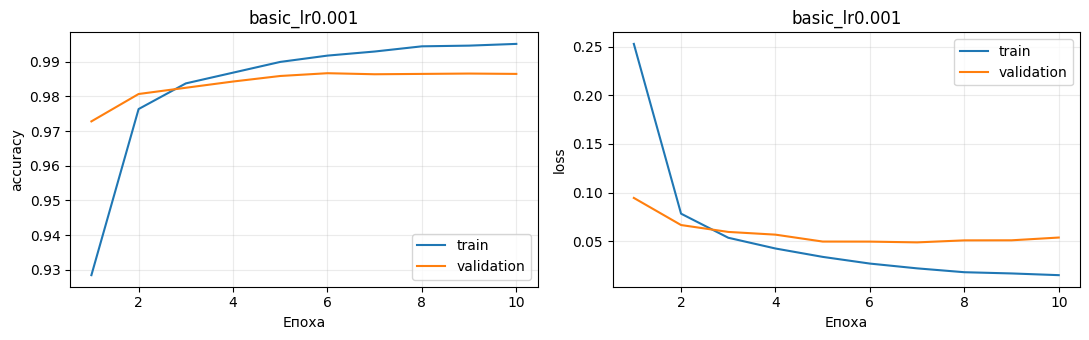

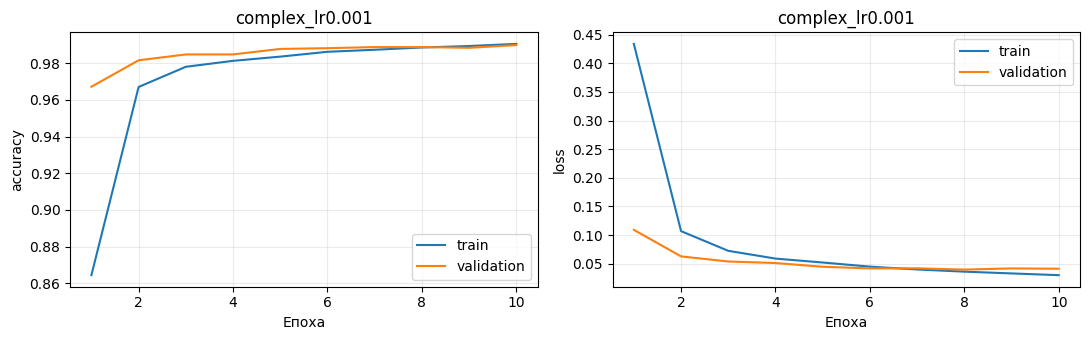

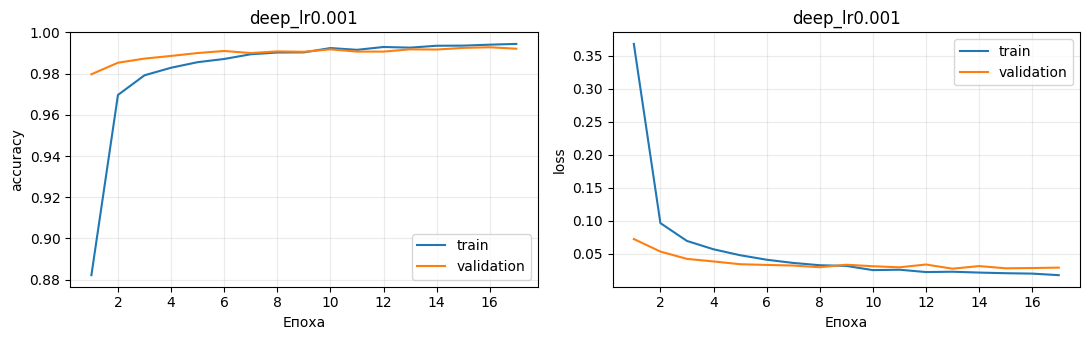

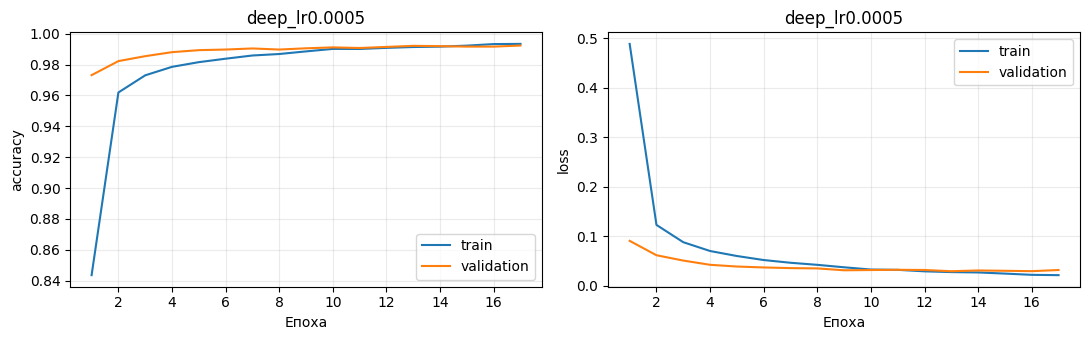

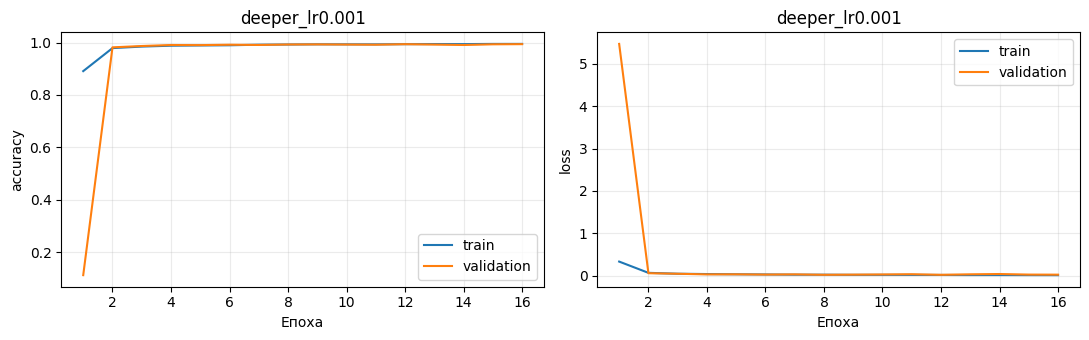

{'run': 'deeper_lr0.001', 'architecture': 'deeper', 'learning_rate': 0.001, 'params': 316010, 'epochs': 16, 'best_epoch': 12, 'val_loss': 0.02513371966779232, 'val_accuracy': 0.9936000108718872, 'seconds': 82.92653831500002}
{'run': 'deep_lr0.001', 'architecture': 'deep', 'learning_rate': 0.001, 'params': 271210, 'epochs': 17, 'best_epoch': 13, 'val_loss': 0.02752259559929371, 'val_accuracy': 0.9918000102043152, 'seconds': 69.95504609199998}
{'run': 'deep_lr0.0005', 'architecture': 'deep', 'learning_rate': 0.0005, 'params': 271210, 'epochs': 17, 'best_epoch': 13, 'val_loss': 0.02920561283826828, 'val_accuracy': 0.9922000169754028, 'seconds': 56.86503963300004}
{'run': 'complex_lr0.001', 'architecture': 'complex', 'learning_rate': 0.001, 'params': 59933, 'epochs': 10, 'best_epoch': 8, 'val_loss': 0.03959169238805771, 'val_accuracy': 0.9887999892234802, 'seconds': 19.922432181999966}
{'run': 'basic_lr0.001', 'architecture': 'basic', 'learning_rate': 0.001, 'params': 592074, 'epochs': 10,

In [8]:
for run, history in cnn_histories.items():  # Повторюємо вкладені дії для кожного елемента циклу.
    plot_history(history, run, f'{run}_learning.png')  # Виконуємо цей крок обчислення для поточного досліду.
for result in sorted(cnn_results, key=lambda r: r['val_loss']):  # Повторюємо вкладені дії для кожного елемента циклу.
    print(result)  # Виводимо поточний результат або перевірочні значення.
winner = min(cnn_results, key=lambda r: r['val_loss'])  # Знаходимо епоху з найменшою перевірочною втратою.
print('Обрано за мінімумом validation loss:', winner)  # Виводимо поточний результат або перевірочні значення.

## 3. П’ять незалежних фолдів
StratifiedKFold зберігає пропорції класів. Кожний фолд отримує нову модель з новими вагами. Тестові 10 000 зображень сюди не потрапляють. Це оцінка стабільності обраної конфігурації; вона обрана на попередньому поділі, тому CV не є повністю незалежним nested-CV тестом.

In [9]:
fold_results = []  # Обчислюємо та зберігаємо значення у змінній fold_results.
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)  # Готуємо стратифіковане розбиття для крос-валідації.
for fold, (fit_idx, valid_idx) in enumerate(kfold.split(cnn_all, labels_train), 1):  # Повторюємо вкладені дії для кожного елемента циклу.
    keras.backend.clear_session(); keras.utils.set_random_seed(100+fold)  # Фіксуємо генератор випадкових чисел для відтворюваного досліду.
    fold_model = build_cnn(winner['architecture'], winner['learning_rate'])  # Обчислюємо та зберігаємо значення у змінній fold_model.
    fold_history = fold_model.fit(cnn_all[fit_idx], cnn_targets[fit_idx],  # Навчаємо модель на тренувальних даних і стежимо за перевірочною вибіркою.
        validation_data=(cnn_all[valid_idx], cnn_targets[valid_idx]),  # Обчислюємо та зберігаємо значення у змінній validation_data.
        epochs=20, batch_size=200, verbose=2,  # Обчислюємо та зберігаємо значення у змінній epochs.
        callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),  # Зупиняємо навчання, якщо перевірочна втрата перестала покращуватися.
                   keras.callbacks.CSVLogger(str(ROOT/'results'/f'cv_fold_{fold}.csv'))])  # Записуємо показники кожної епохи у CSV-файл.
    fold_loss, fold_acc = fold_model.evaluate(cnn_all[valid_idx], cnn_targets[valid_idx], verbose=0)  # Оцінюємо готову модель на окремих даних.
    fold_results.append(dict(fold=fold, accuracy=float(fold_acc), loss=float(fold_loss),  # Обчислюємо та зберігаємо значення у змінній fold_results.append(dict(fold.
        best_epoch=int(np.argmin(fold_history.history['val_loss'])+1)))  # Знаходимо епоху з найменшою перевірочною втратою.
    (ROOT/'results/cross_validation.json').write_text(json.dumps(fold_results, indent=2), encoding='utf-8')  # Обчислюємо та зберігаємо значення у змінній (ROOT/'results/cross_validation.json').write_text(json.dumps(fold_results, indent.
print('CV mean accuracy:', np.mean([f['accuracy'] for f in fold_results]))  # Виводимо поточний результат або перевірочні значення.
print('CV std accuracy:', np.std([f['accuracy'] for f in fold_results], ddof=1))  # Виводимо поточний результат або перевірочні значення.

Epoch 1/20
240/240 - 12s - 51ms/step - accuracy: 0.8712 - loss: 0.4040 - val_accuracy: 0.1123 - val_loss: 4.3023
Epoch 2/20
240/240 - 4s - 16ms/step - accuracy: 0.9767 - loss: 0.0801 - val_accuracy: 0.9748 - val_loss: 0.0877
Epoch 3/20
240/240 - 4s - 18ms/step - accuracy: 0.9835 - loss: 0.0567 - val_accuracy: 0.9865 - val_loss: 0.0449
Epoch 4/20
240/240 - 4s - 16ms/step - accuracy: 0.9864 - loss: 0.0466 - val_accuracy: 0.9888 - val_loss: 0.0347
Epoch 5/20
240/240 - 4s - 16ms/step - accuracy: 0.9880 - loss: 0.0400 - val_accuracy: 0.9913 - val_loss: 0.0270
Epoch 6/20
240/240 - 4s - 17ms/step - accuracy: 0.9894 - loss: 0.0360 - val_accuracy: 0.9923 - val_loss: 0.0261
Epoch 7/20
240/240 - 4s - 17ms/step - accuracy: 0.9914 - loss: 0.0296 - val_accuracy: 0.9925 - val_loss: 0.0268
Epoch 8/20
240/240 - 4s - 17ms/step - accuracy: 0.9914 - loss: 0.0293 - val_accuracy: 0.9918 - val_loss: 0.0275
Epoch 9/20
240/240 - 4s - 17ms/step - accuracy: 0.9921 - loss: 0.0261 - val_accuracy: 0.9908 - val_loss

## 4. Фінальна модель
Кількість епох — медіана найкращих епох п’яти фолдів. Навчаємо заново на всіх 60 000 прикладах. Далі відкриваємо недоторканий test: accuracy, loss, precision/recall/F1, матриця помилок. Окремо оцінюємо кожну архітектуру після завершення вибору: результати test не впливають на winner.

Epoch 1/6
300/300 - 12s - 40ms/step - accuracy: 0.8970 - loss: 0.3148
Epoch 2/6
300/300 - 4s - 15ms/step - accuracy: 0.9798 - loss: 0.0692
Epoch 3/6
300/300 - 4s - 15ms/step - accuracy: 0.9858 - loss: 0.0499
Epoch 4/6
300/300 - 4s - 15ms/step - accuracy: 0.9885 - loss: 0.0394
Epoch 5/6
300/300 - 5s - 15ms/step - accuracy: 0.9898 - loss: 0.0353
Epoch 6/6
300/300 - 5s - 15ms/step - accuracy: 0.9912 - loss: 0.0303
{'architecture': 'deeper', 'learning_rate': 0.001, 'final_epochs': 6, 'test_accuracy': 0.9909999966621399, 'test_loss': 0.033406443893909454, 'test_errors': 90, 'parameters': 316010, 'cv_mean': 0.9922666668891906, 'cv_std': 0.0008885868533398558}


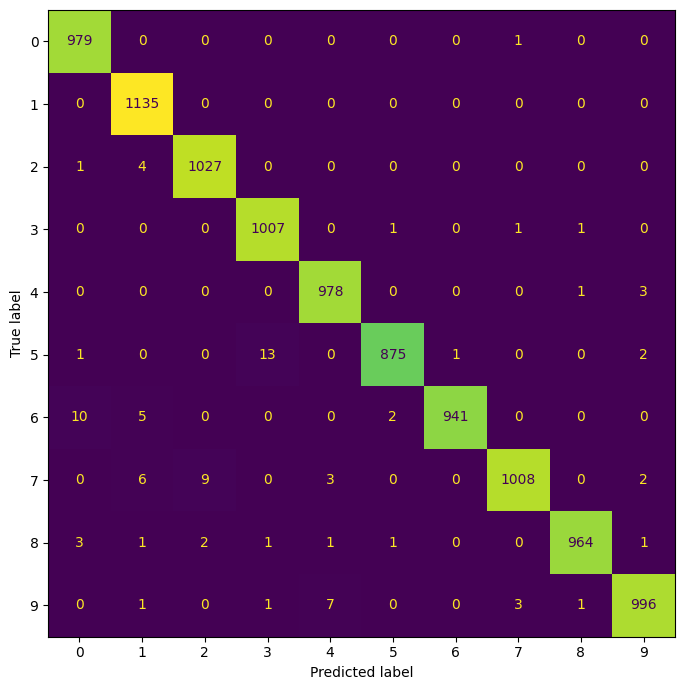

[{'run': 'basic_lr0.001', 'test_accuracy': 0.9873999953269958, 'test_loss': 0.040114667266607285}, {'run': 'complex_lr0.001', 'test_accuracy': 0.9898999929428101, 'test_loss': 0.02780221216380596}, {'run': 'deep_lr0.001', 'test_accuracy': 0.9948999881744385, 'test_loss': 0.017156114801764488}, {'run': 'deep_lr0.0005', 'test_accuracy': 0.9934999942779541, 'test_loss': 0.019086234271526337}, {'run': 'deeper_lr0.001', 'test_accuracy': 0.9944999814033508, 'test_loss': 0.021721189841628075}]


In [10]:
final_epochs = max(1, int(np.median([f['best_epoch'] for f in fold_results])))  # Обчислюємо та зберігаємо значення у змінній final_epochs.
keras.backend.clear_session(); keras.utils.set_random_seed(2026)  # Фіксуємо генератор випадкових чисел для відтворюваного досліду.
final_model = build_cnn(winner['architecture'], winner['learning_rate'])  # Обчислюємо та зберігаємо значення у змінній final_model.
final_history = final_model.fit(cnn_all, cnn_targets, epochs=final_epochs, batch_size=200, verbose=2,  # Навчаємо модель на тренувальних даних і стежимо за перевірочною вибіркою.
    callbacks=[keras.callbacks.CSVLogger(str(ROOT/'results/final_epochs.csv'))])  # Записуємо показники кожної епохи у CSV-файл.
final_model.save(ROOT/'models/best_mnist_cnn.keras')  # Зберігаємо навчену модель або результат на диск.
reloaded_model = keras.models.load_model(ROOT/'models/best_mnist_cnn.keras')  # Обчислюємо та зберігаємо значення у змінній reloaded_model.
final_loss, final_accuracy = reloaded_model.evaluate(cnn_test, cnn_test_targets, verbose=0)  # Оцінюємо готову модель на окремих даних.
final_probs = reloaded_model.predict(cnn_test, batch_size=200, verbose=0)  # Обчислюємо ймовірності класів для вхідних зразків.
final_predictions = np.argmax(final_probs, axis=1)  # Беремо індекс класу з найбільшою ймовірністю.
report = classification_report(labels_test, final_predictions, output_dict=True)  # Обчислюємо та зберігаємо значення у змінній report.
final_summary = dict(architecture=winner['architecture'], learning_rate=winner['learning_rate'],  # Обчислюємо та зберігаємо значення у змінній final_summary.
    final_epochs=final_epochs, test_accuracy=float(final_accuracy), test_loss=float(final_loss),  # Обчислюємо та зберігаємо значення у змінній final_epochs.
    test_errors=int(np.sum(final_predictions != labels_test)), parameters=reloaded_model.count_params(),  # Обчислюємо та зберігаємо значення у змінній test_errors.
    cv_mean=float(np.mean([f['accuracy'] for f in fold_results])), cv_std=float(np.std([f['accuracy'] for f in fold_results], ddof=1)))  # Обчислюємо та зберігаємо значення у змінній cv_mean.
(ROOT/'results/final_summary.json').write_text(json.dumps(final_summary, indent=2), encoding='utf-8')  # Обчислюємо та зберігаємо значення у змінній (ROOT/'results/final_summary.json').write_text(json.dumps(final_summary, indent.
(ROOT/'results/classification_report.json').write_text(json.dumps(report, indent=2), encoding='utf-8')  # Обчислюємо та зберігаємо значення у змінній (ROOT/'results/classification_report.json').write_text(json.dumps(report, indent.
np.save(ROOT/'results/test_probabilities.npy', final_probs)  # Зберігаємо навчену модель або результат на диск.
print(final_summary)  # Виводимо поточний результат або перевірочні значення.
fig, ax = plt.subplots(figsize=(8,7)); ConfusionMatrixDisplay.from_predictions(labels_test, final_predictions, ax=ax, colorbar=False)  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
fig.tight_layout(); fig.savefig(ROOT/'results/confusion_matrix.png', dpi=150); plt.show()  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
architecture_tests = []  # Обчислюємо та зберігаємо значення у змінній architecture_tests.
for result in cnn_results:  # Повторюємо вкладені дії для кожного елемента циклу.
    tested = keras.models.load_model(ROOT/'models'/f"{result['run']}.keras")  # Обчислюємо та зберігаємо значення у змінній tested.
    loss, acc = tested.evaluate(cnn_test, cnn_test_targets, batch_size=200, verbose=0)  # Оцінюємо готову модель на окремих даних.
    architecture_tests.append(dict(run=result['run'], test_accuracy=float(acc), test_loss=float(loss)))  # Обчислюємо та зберігаємо значення у змінній architecture_tests.append(dict(run.
(ROOT/'results/architecture_test_results.json').write_text(json.dumps(architecture_tests, indent=2), encoding='utf-8')  # Обчислюємо та зберігаємо значення у змінній (ROOT/'results/architecture_test_results.json').write_text(json.dumps(architecture_tests, indent.
print(architecture_tests)  # Виводимо поточний результат або перевірочні значення.

## Висновок
Файл best_mnist_cnn.keras містить архітектуру та навчені ваги. Підбір завершено до перегляду test і зовнішніх зображень. Висока точність MNIST не гарантує правильних відповідей на фото іншого походження. Перевірка збереженої моделі та зовнішніх цифр — у ноутбуці 05.

Збережений запуск: за validation loss обрано deeper з Adam 0.001; 5-fold — 99.23% ± 0.089 в.п. Після нового навчання на всіх 60 000 прикладах протягом 6 епох тестова accuracy — 99.10% (90 помилок). Checkpoint deeper на поділі 50k/10k дав 99.45% test; deep з Adam 0.001 — 99.49%. Вибір не змінено за тестом, усі checkpoint збережені.